# Assignment 6.1

Name: Francisco Gutierrez  
Date: October 19, 2026


For this assignment, you will refer to the textbook to solve the practice exercises. **Use Python to answer any coding problems (not R, even if indicated in your textbook).** Use Jupyter Notebook, Google Colab, or a similar software program to complete your assignment. Submit your answers as a **PDF or HTML** file. As a best practice, always label your axes and provide titles for any graphs generated on this assignment. Round all quantitative answers to 2 decimal places.

## Problem 6.1.

For the Scottish hill `Races` data, a linear model can predict men’s record times from women’s record times.  
http://stat4ds.rwth-aachen.de/data/ScotsRaces.dat


(a)  Show the scatterplot and report the prediction equation. Predict the men’s record time for the Highland Fling, for which timeW = 490.05 minutes.


The prediction equation is **timeM = ?2.83 + 0.87 timeW**. The predicted Highland Fling record is **423.94 minutes** (calculated with unrounded coefficients). 

The scatterplot shows a strong positive, approximately linear association. The fitted equation and Highland Fling prediction (minutes) are reported below. The prediction estimates a record time, rather than an individual runner's time.


Predicted timeM = -2.83 +0.87*timeW
Highland Fling prediction: 423.94 minutes


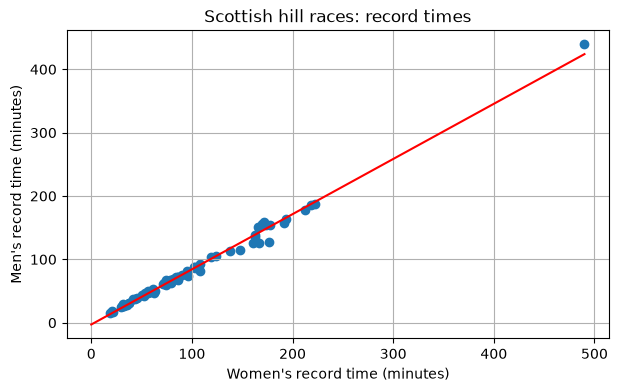

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display
pd.options.display.float_format = '{:.2f}'.format
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.grid': True})
DATA = Path('data')
def load(name):
    path = DATA / f'{name}.dat'
    if path.exists():
        return pd.read_csv(path, sep=r'\s+')
    return pd.read_csv(f'https://stat4ds.rwth-aachen.de/data/{name}.dat', sep=r'\s+')
def equation(model, response):
    terms = [f'{value:+.2f}*{name}' for name, value in model.params.items() if name != 'Intercept']
    print(f"{response} = {model.params.get('Intercept', 0):.2f} " + ' '.join(terms))
def coefficients(model):
    table = pd.DataFrame({'Estimate': model.params, 'SE': model.bse, 'p-value': model.pvalues})
    table['p-value'] = table['p-value'].map(lambda p: '< 0.01' if p < .005 else f'{p:.2f}')
    display(table)
races = load('ScotsRaces')
race_fit = smf.ols('timeM ~ timeW', races).fit()
equation(race_fit, 'Predicted timeM')
print(f"Highland Fling prediction: {race_fit.predict(pd.DataFrame({'timeW':[490.05]})).iloc[0]:.2f} minutes")
plt.scatter(races.timeW, races.timeM)
x = np.linspace(0, races.timeW.max(), 200)
plt.plot(x, race_fit.predict(pd.DataFrame({'timeW':x})), color='red')
plt.xlabel("Women's record time (minutes)"); plt.ylabel("Men's record time (minutes)")
plt.title('Scottish hill races: record times'); plt.show()


(b) Find and interpret the correlation.

The correlation rounds to **1.00**, indicating an extremely strong positive linear relationship; rounding does not imply that every point lies exactly on a line. 

The positive correlation indicates that races with longer women's record times tend to have longer men's record times. It describes association between race records, not a causal effect.


In [2]:
print(f'Pearson correlation: {races.timeW.corr(races.timeM):.2f}')


Pearson correlation: 1.00


(c) We could impose the natural constraint that when timeW = 0, then timeM = 0. Fit the model $E(Y_i)=\beta x_i.$ Interpret the estimated slope.

The fitted equation is **timeM = 0.85 timeW**; the slope is **0.85 minutes per minute**. 

With the intercept constrained to zero, each additional minute in the women's record corresponds to the estimated slope in additional minutes of the predicted men's record. This constraint is plausible at zero duration but changes the least squares fit.


In [3]:
race_zero = smf.ols('timeM ~ 0 + timeW', races).fit()
equation(race_zero, 'Predicted timeM')
print(f'Slope: {race_zero.params.timeW:.2f} minutes per minute')


Predicted timeM = 0.00 +0.85*timeW
Slope: 0.85 minutes per minute


## Problem 6.2.

For advanced industrialized nations, the Firearms data file at the text website shows annual homicide rates (per million population) and the number of firearms (per 100 people), with data taken from Wikipedia and [smallarmssurvey.org](smallarmssurvey.org).

(a) Construct a scatterplot and highlight any observations that fall apart from the general trend.

The United States lies well above and to the right of the other nations, with unusually high firearms ownership and deaths. It has substantial leverage because its predictor value is far from the others.


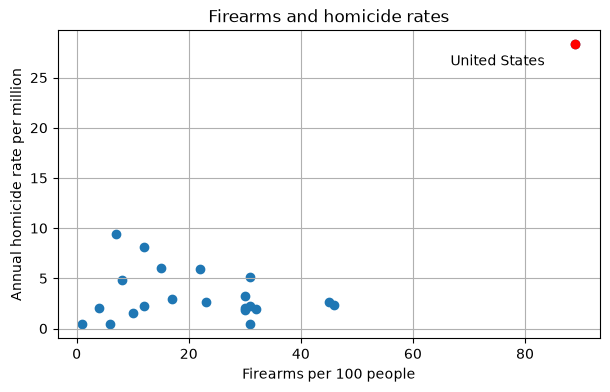

In [4]:
firearms = load('Firearms')
plt.scatter(firearms.firearms, firearms.deaths)
us = firearms.loc[firearms.Nation == 'US'].iloc[0]
plt.scatter(us.firearms, us.deaths, color='red')
plt.annotate('United States', (us.firearms, us.deaths), xytext=(-90,-15), textcoords='offset points')
plt.xlabel('Firearms per 100 people'); plt.ylabel('Annual homicide rate per million')
plt.title('Firearms and homicide rates'); plt.show()


(b) Find the correlation with and without the outlying observation. Why is it so different in the two cases?

With the US, **r = 0.63**; without it, **r = ?0.18**. 

The US observation creates a positive association across the full sample. Removing it changes the correlation substantially because most remaining nations have a narrow range of homicide rates and no comparable positive trend. Neither correlation establishes causality.


In [5]:
firearms_no_us = firearms.loc[firearms.Nation != 'US']
print(f'With US: r = {firearms.firearms.corr(firearms.deaths):.2f}')
print(f'Without US: r = {firearms_no_us.firearms.corr(firearms_no_us.deaths):.2f}')


With US: r = 0.63
Without US: r = -0.18


(c) Fit the linear regression model with and without the outlying observation, and note how influential an outlier can be on the fit.

With the US: **deaths = ?0.27 + 0.19 firearms**. Without the US: **deaths = 3.91 ? 0.03 firearms**. 

The equations below quantify the change in slope after removing the US. The large change demonstrates influence: a single observation can materially change the fitted relationship.


Predicted deaths (with US) = -0.27 +0.19*firearms
Predicted deaths (without US) = 3.91 -0.03*firearms


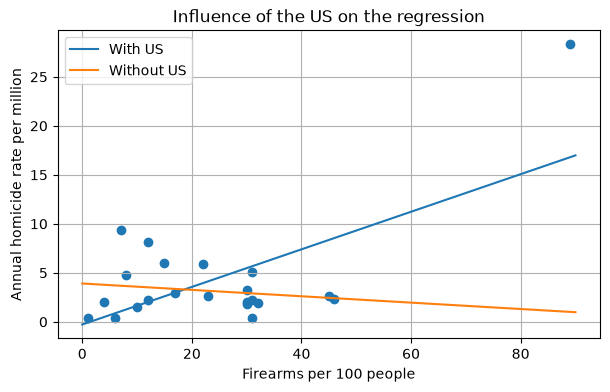

In [6]:
fire_all = smf.ols('deaths ~ firearms', firearms).fit()
fire_reduced = smf.ols('deaths ~ firearms', firearms_no_us).fit()
equation(fire_all, 'Predicted deaths (with US)')
equation(fire_reduced, 'Predicted deaths (without US)')
x = np.linspace(0,90,200)
plt.scatter(firearms.firearms, firearms.deaths)
for fit,label in [(fire_all,'With US'),(fire_reduced,'Without US')]:
    plt.plot(x, fit.predict(pd.DataFrame({'firearms':x})), label=label)
plt.xlabel('Firearms per 100 people'); plt.ylabel('Annual homicide rate per million')
plt.title('Influence of the US on the regression'); plt.legend(); plt.show()


## Problem 6.5.

For the `Covid19` data file at the text website:  
http://stat4ds.rwth-aachen.de/data/Covid19.dat 

(a) Construct the two scatterplots shown in Figure 6.3.

Cases rise in a curved pattern on the original scale. The natural logarithm makes the association with time approximately linear, consistent with early exponential growth.


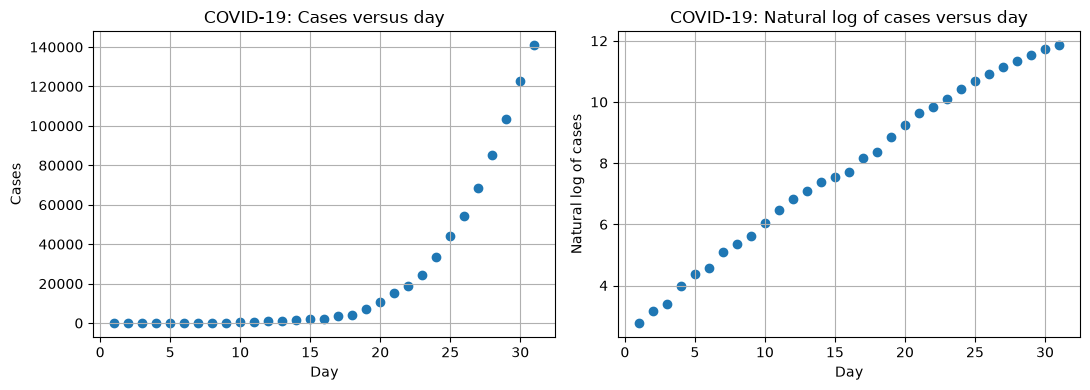

In [7]:
covid = load('Covid19')
covid['log_cases'] = np.log(covid.cases)
fig, axes = plt.subplots(1,2,figsize=(11,4))
for ax,col,label in zip(axes,['cases','log_cases'],['Cases','Natural log of cases']):
    ax.scatter(covid.day,covid[col]); ax.set(xlabel='Day',ylabel=label,title=f'COVID-19: {label} versus day')
plt.tight_layout(); plt.show()


(b) Find and interpret the correlation between time and (i) cases, (ii) log(cases).

The correlations are **0.79** for cases and **1.00** for log(cases), after rounding. The latter is nearly perfect, rather than exactly perfect. 

Both correlations are positive. The stronger correlation on the log scale indicates a closer linear relationship with time after transformation. These cumulative time series observations are not independent observations for ordinary regression inference.


In [8]:
print(f'Time and cases: r = {covid.day.corr(covid.cases):.2f}')
print(f'Time and log(cases): r = {covid.day.corr(covid.log_cases):.2f}')


Time and cases: r = 0.79
Time and log(cases): r = 1.00


(c)  Fit the linear model for the log-transformed counts and report the prediction equation.$^{29}.$ Explain why the predicted count at day $x+1$ equals the predicted count at day $x$ multiplied by $\text{exp}(\hat\beta_1)=1.36.$

The fitted equation is **log(cases) = 2.84 + 0.31 day**, using the natural logarithm. 

For the fitted equation below, exponentiating gives $\widehat{cases}(x)=\exp(\hat\beta_0+\hat\beta_1x)$. Thus $\widehat{cases}(x+1)/\widehat{cases}(x)=\exp(\hat\beta_1)$, approximately 1.36: about 36% daily growth. Exponentiating the fitted log gives a geometric trend (and a conditional median under lognormal errors), not automatically an unbiased arithmetic mean of counts.


In [9]:
covid_fit = smf.ols('log_cases ~ day', covid).fit()
equation(covid_fit,'Predicted log(cases)')
print(f'Daily multiplier: {np.exp(covid_fit.params.day):.2f}')
print(f'Daily growth: {100*np.expm1(covid_fit.params.day):.2f}%')


Predicted log(cases) = 2.84 +0.31*day
Daily multiplier: 1.36
Daily growth: 36.18%


## Problem 6.8.

Refer to the example in Section 6.2.5 of the crime rate in Florida counties.

(a) Explain what it means when we say these data exhibit *Simpson’s paradox*. What could cause this change in the direction of the association between crime rate and education
when we adjust for urbanization?

Simpson's paradox occurs when the direction of an aggregate association reverses after adjusting for a third variable. Here, education and crime have a positive association across counties, but the education coefficient becomes negative after controlling for urbanization. More urban counties tend to have both more education and more reported crime, so urbanization can confound the unadjusted association. Adjustment alone does not establish a causal effect.


In [10]:
florida = load('Florida')
fl_simple = smf.ols('Crime ~ HS',florida).fit()
fl_adjusted = smf.ols('Crime ~ HS + Urban',florida).fit()
equation(fl_simple,'Predicted crime (unadjusted)')
equation(fl_adjusted,'Predicted crime (adjusted)')


Predicted crime (unadjusted) = -50.86 +1.49*HS
Predicted crime (adjusted) = 59.12 -0.58*HS +0.68*Urban


(b) Using the Florida data file, construct the scatterplot between *x* = education (HS) and *y* = income (Income), for which the correlation is 0.79. If we had data at the individual
level as well as aggregated for a county, sketch a scatterplot to show that at that level the correlation could be much weaker. So, predictions about individuals based on the
behavior of aggregate groups, known as the *ecological fallacy*, can be quite misleading.

The observed county correlation is about 0.79. County percentages and median incomes do not identify the association among individuals. The second panel is a hypothetical individual-level sketch, with substantial income variation at either education category; it is simulated, not observed Florida data. Individuals have a high school completion indicator rather than a county completion percentage.


County correlation: 0.79


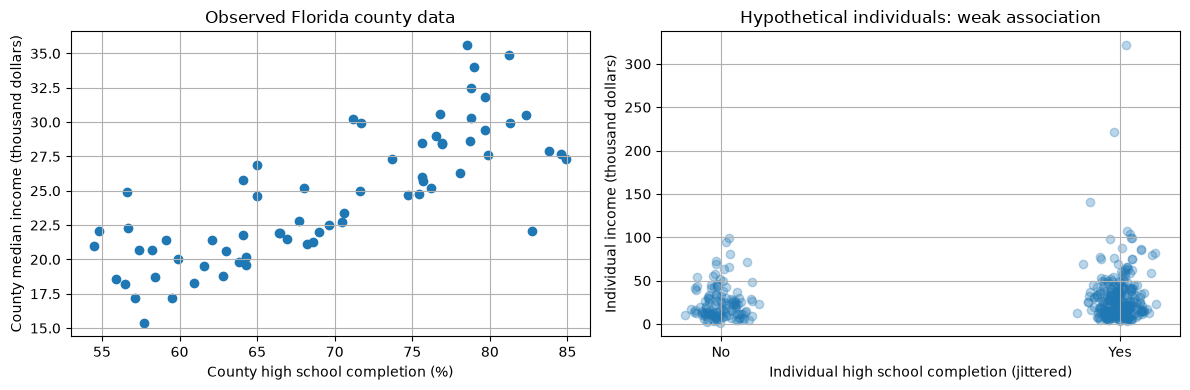

In [11]:
income_fit = smf.ols('Income ~ HS',florida).fit()
print(f'County correlation: {florida.HS.corr(florida.Income):.2f}')
rng = np.random.default_rng(500)
educated = rng.binomial(1,.7,400)
individual_income = np.exp(3 + .12*educated + rng.normal(0,.8,400))
fig,axes = plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(florida.HS,florida.Income)
axes[0].set(xlabel='County high school completion (%)',ylabel='County median income (thousand dollars)',title='Observed Florida county data')
axes[1].scatter(educated+rng.normal(0,.035,400),individual_income,alpha=.3)
axes[1].set(xticks=[0,1],xticklabels=['No','Yes'],xlabel='Individual high school completion (jittered)',ylabel='Individual income (thousand dollars)',title='Hypothetical individuals: weak association')
plt.tight_layout();plt.show()


(c) Refer to (b), in which *x* falls between 54.5 and 84.9. Is it sensible to use the least squares line to predict a county’s median income if *x* = 0? Sketch a hypothetical true relationship between *x* and *E(Y)* to show the danger of *extrapolation*, using a fitted line to predict *E(Y)* far from the observed *x* values.

Predicting at 0% high school completion is not sensible: the observed range is 54.5%–84.9%. A straight line that describes that range need not describe counties far outside it. The dashed curve is an illustrative possible mean relationship, not a fitted or known relationship; it stays close to the line in the data range but diverges near zero.


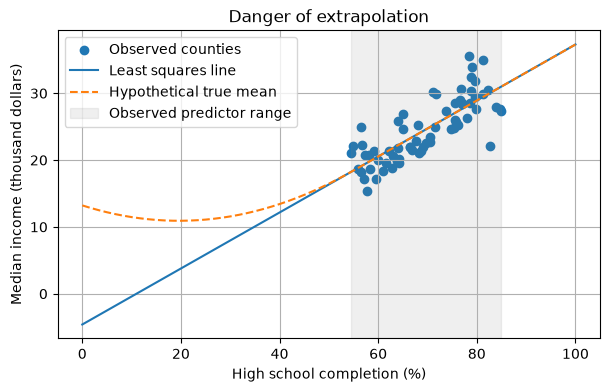

Linear extrapolation at HS = 0: -4.60 thousand dollars


In [12]:
x = np.linspace(0,100,300)
yline = income_fit.predict(pd.DataFrame({'HS':x}))
hypothetical = yline + .006*np.maximum(54.5-x,0)**2
plt.scatter(florida.HS,florida.Income,label='Observed counties')
plt.plot(x,yline,label='Least squares line')
plt.plot(x,hypothetical,'--',label='Hypothetical true mean')
plt.axvspan(54.5,84.9,color='gray',alpha=.12,label='Observed predictor range')
plt.xlabel('High school completion (%)');plt.ylabel('Median income (thousand dollars)')
plt.title('Danger of extrapolation');plt.legend();plt.show()
print(f'Linear extrapolation at HS = 0: {income_fit.params.Intercept:.2f} thousand dollars')


## Problem 6.10.

The `Students` data file shows responses on variables summarized in Exercise 1.2.

(a) Fit the linear model using *hsgpa* = high school GPA, *tv* = weekly hours watching TV, and *sport* = weekly hours participating in sports as predictors of *cogpa* = college GPA. Report the prediction equation. What do the *P*-values suggest?

The prediction equation and coefficient tests are below. At the 0.05 level, high school GPA provides evidence of an association with college GPA after adjusting for TV and sports. TV and sports do not provide strong evidence of separate associations in this sample. Small p-values are shown as < 0.01 rather than rounded to zero.


In [13]:
students = load('Students')
student_fit = smf.ols('cogpa ~ hsgpa + tv + sport',students).fit()
equation(student_fit,'Predicted college GPA')
coefficients(student_fit)


Predicted college GPA = 2.82 +0.21*hsgpa +0.00*tv -0.01*sport


,Estimate,SE,p-value
Intercept,2.82,0.37,< 0.01
hsgpa,0.21,0.10,0.04
tv,0.00,0.01,0.63
sport,-0.01,0.01,0.23


(b)  Summarize the estimated effect of *hsgpa.*

The estimated adjusted effect is **0.21 GPA points**, with a **95% confidence interval of (0.01, 0.41)**. 

The high school GPA coefficient is the predicted increase in college GPA for a one-point higher high school GPA, holding weekly TV and sports hours constant. The confidence interval below describes uncertainty in that adjusted association; it does not imply a causal effect.


In [14]:
lo,hi = student_fit.conf_int().loc['hsgpa']
print(f'Adjusted hsgpa effect: {student_fit.params.hsgpa:.2f} college GPA points per high school GPA point')
print(f'95% confidence interval: ({lo:.2f}, {hi:.2f})')


Adjusted hsgpa effect: 0.21 college GPA points per high school GPA point
95% confidence interval: (0.01, 0.41)


(c) Report and interpret $R^2$, adjusted $R^2$, and the multiple correlation.

**R? = 0.10** (10.45% of variation explained), **adjusted R? = 0.06**, and **multiple correlation = 0.32**. 

R-squared is the proportion of sample variation in college GPA explained jointly by the three predictors. Adjusted R-squared penalizes model size. The multiple correlation is the positive square root of R-squared, equal to the correlation between observed and fitted college GPAs for this model with an intercept.


In [15]:
print(f'R-squared: {student_fit.rsquared:.2f} ({100*student_fit.rsquared:.2f}% explained)')
print(f'Adjusted R-squared: {student_fit.rsquared_adj:.2f}')
print(f'Multiple correlation: {np.sqrt(student_fit.rsquared):.2f}')


R-squared: 0.10 (10.45% explained)
Adjusted R-squared: 0.06
Multiple correlation: 0.32


## Problem 6.12.

For the `UN` data file at the book’s website (see Exercise 1.24), construct a multiple regression model predicting Internet using all the other variables. Use the concept of multicollinearity to explain why adjusted $R^2$ is not dramatically greater than when GDP is the sole predictor. Compare the estimated GDP effect in the bivariate model and the multiple regression model and explain why it is so much weaker in the multiple regression model.

Adjusted R? rises from **0.76** with GDP alone to **0.82** with all numeric predictors. The GDP coefficient falls from **1.41** to **0.44**; HDI has a VIF of **10.84**. 

Nation is an identifier, so all other **numeric** variables are predictors. Both models use identical complete cases for a fair comparison. GDP shares information with development measures such as HDI and GII. Its bivariate coefficient includes shared associations with those variables; its multiple-regression coefficient measures only the remaining association conditional on them. Correlated predictors yield unstable individual coefficients and larger standard errors. Adding predictors therefore need not improve adjusted R-squared much. The correlation matrix and variance inflation factors below assess this overlap.


In [16]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
un = load('UN')
predictors = [c for c in un.columns if c not in ['Nation','Internet']]
un_complete = un.dropna(subset=['Internet']+predictors)
un_simple = smf.ols('Internet ~ GDP',un_complete).fit()
un_multiple = smf.ols('Internet ~ '+' + '.join(predictors),un_complete).fit()
equation(un_multiple,'Predicted Internet (%)')
coefficients(un_multiple)
display(pd.DataFrame({'Model':['GDP only','All numeric predictors'],'n':[un_simple.nobs,un_multiple.nobs],'Adjusted R2':[un_simple.rsquared_adj,un_multiple.rsquared_adj],'GDP effect':[un_simple.params.GDP,un_multiple.params.GDP]}))
display(un_complete[predictors].corr())
X_vif = sm.add_constant(un_complete[predictors])
display(pd.DataFrame({'Predictor':predictors,'VIF':[variance_inflation_factor(X_vif.values,i+1) for i in range(len(predictors))]}))


Predicted Internet (%) = 11.16 +0.44*GDP +55.85*HDI -72.43*GII +4.09*Fertility +0.31*CO2 +0.38*Homicide +0.01*Prison


,Estimate,SE,p-value
Intercept,11.16,38.77,0.78
GDP,0.44,0.29,0.14
HDI,55.85,46.65,0.24
GII,-72.43,25.32,0.01
Fertility,4.09,3.07,0.19
CO2,0.31,0.65,0.64
Homicide,0.38,0.30,0.22
Prison,0.01,0.02,0.62


,Model,n,Adjusted R2,GDP effect
0,GDP only,42.00,0.76,1.41
1,All numeric predictors,42.00,0.82,0.44


,GDP,HDI,GII,Fertility,CO2,Homicide,Prison
GDP,1.00,0.90,-0.85,-0.49,0.67,-0.41,-0.00
HDI,0.90,1.00,-0.88,-0.67,0.68,-0.43,0.04
GII,-0.85,-0.88,1.00,0.60,-0.55,0.51,0.22
Fertility,-0.49,-0.67,0.60,1.00,-0.45,0.31,-0.09
CO2,0.67,0.68,-0.55,-0.45,1.00,-0.17,0.37
Homicide,-0.41,-0.43,0.51,0.31,-0.17,1.00,0.33
Prison,-0.00,0.04,0.22,-0.09,0.37,0.33,1.00


,Predictor,VIF
0,GDP,7.34
1,HDI,10.84
2,GII,7.16
3,Fertility,2.19
4,CO2,2.59
5,Homicide,1.47
6,Prison,1.92


## Problem 7.1.

For the `Houses` data file described in Section 7.1.3, consider $Y$ = selling price, $x_1$ = tax bill (in dollars), and $x_2$ = whether the house is new.

(a) Form the scatterplot of $y$ and $x_1$. Does the normal GLM structure of constant variability in $y$ seem approproate? If not, how does it seem to be violated?

The vertical spread of selling prices tends to increase with tax bills. This suggests heteroscedasticity: a normal model with constant conditional variance may be inappropriate. The scatterplot is a preliminary check because tax alone does not account for new-house status.


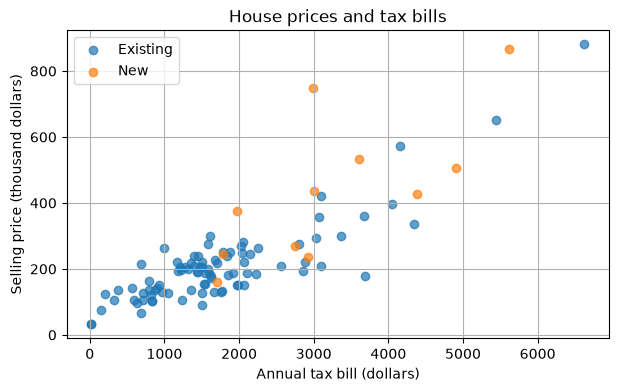

In [17]:
houses = load('Houses')
for new,label in [(0,'Existing'),(1,'New')]:
    d = houses.loc[houses.new == new]
    plt.scatter(d.taxes,d.price,label=label,alpha=.7)
plt.xlabel('Annual tax bill (dollars)');plt.ylabel('Selling price (thousand dollars)')
plt.title('House prices and tax bills');plt.legend();plt.show()


(b) Using the identity link function, fit the (i) normal GLM, (ii) gamma GLM. For each model, interpret the effect of $x_2$.

For normal and gamma models, the estimated new-house premiums are **86.20** and **80.55 thousand dollars**, respectively, at a fixed tax bill. 

With an identity link, each new-house coefficient is an additive difference in predicted selling price (thousand dollars) between a new and existing house with the same tax bill. The two distributions weight observations differently, so their estimated differences can differ. Gamma identity models require positive fitted means, checked below.


In [18]:
normal_fit = smf.glm('price ~ taxes + new',houses,family=sm.families.Gaussian(sm.families.links.Identity())).fit()
# Identity is not globally positivity-preserving; check fitted means on these data.
import warnings
from statsmodels.tools.sm_exceptions import DomainWarning
with warnings.catch_warnings():
    warnings.simplefilter('ignore',DomainWarning)
    gamma_fit = smf.glm('price ~ taxes + new',houses,family=sm.families.Gamma(sm.families.links.Identity())).fit(maxiter=200)
assert gamma_fit.converged and (gamma_fit.fittedvalues > 0).all()
for label,fit in [('Normal',normal_fit),('Gamma',gamma_fit)]:
    equation(fit,f'{label} predicted price (thousand dollars)')
    print(f'{label}: new-house difference = {fit.params.new:.2f} thousand dollars; minimum fitted mean = {fit.fittedvalues.min():.2f}')


Normal predicted price (thousand dollars) = 41.97 +0.10*taxes +86.20*new

Normal: new-house difference = 86.20 thousand dollars; minimum fitted mean = 43.87
Gamma predicted price (thousand dollars) = 63.22 +0.08*taxes +80.55*new
Gamma: new-house difference = 80.55 thousand dollars; minimum fitted mean = 64.89


(c) For each model, describe how the estimated variability in selling prices varies as the mean selling price varies from 100 thousand to 500 thousand dollars.

For the normal GLM, $\operatorname{Var}(Y\mid x)=\phi$, so the standard deviation is constant. For the gamma GLM, $\operatorname{Var}(Y\mid x)=\phi\mu^2$, so the standard deviation is $\sqrt{\phi}\mu$; increasing the mean from 100 to 500 thousand dollars multiplies the standard deviation by five and the variance by 25. The table uses Pearson dispersion estimates and expresses standard deviations in thousand dollars.


In [19]:
means = np.array([100.,200.,300.,400.,500.])
display(pd.DataFrame({'Mean price (thousand dollars)':means,'Normal SD':np.repeat(np.sqrt(normal_fit.scale),5),'Gamma SD':np.sqrt(gamma_fit.scale)*means,'Normal variance':np.repeat(normal_fit.scale,5),'Gamma variance':gamma_fit.scale*means**2}))


,Mean price (thousand dollars),Normal SD,Gamma SD,Normal variance,Gamma variance
0,100.00,78.82,29.55,6212.74,873.18
1,200.00,78.82,59.10,6212.74,3492.73
2,300.00,78.82,88.65,6212.74,7858.65
3,400.00,78.82,118.20,6212.74,13970.93
4,500.00,78.82,147.75,6212.74,21829.58


(d) Which model is preferred according to AIC?

The **gamma model is preferred**: AIC **1106.69**, compared with **1162.18** for the normal model. 

Prefer the model with smaller AIC, balancing likelihood fit against model complexity. Both models use the same response scale and observations. For a consistent likelihood comparison, the gamma dispersion is estimated by maximum likelihood below rather than using its default Pearson estimate.


In [20]:
from scipy.optimize import minimize_scalar
from scipy.special import gammaln
mu = np.asarray(gamma_fit.fittedvalues)
y = houses.price.to_numpy()
def gamma_loglik(log_shape):
    k = np.exp(log_shape)
    return np.sum(k*np.log(k/mu)-gammaln(k)+(k-1)*np.log(y)-k*y/mu)
opt = minimize_scalar(lambda z: -gamma_loglik(z),bounds=(-10,15),method='bounded')
assert opt.success
normal_var_mle = np.mean((y-normal_fit.fittedvalues)**2)
normal_ll = np.sum(-.5*(np.log(2*np.pi*normal_var_mle)+(y-normal_fit.fittedvalues)**2/normal_var_mle))
# Three regression coefficients plus one estimated dispersion in each model.
aics = pd.Series({'Normal':-2*normal_ll+2*4,'Gamma':2*opt.fun+2*4},name='AIC (ML dispersion)')
display(aics.to_frame())
print(f'Preferred by AIC: {aics.idxmin()}')


,AIC (ML dispersion)
Normal,1162.18
Gamma,1106.69


Preferred by AIC: Gamma


## Problem 7.5.

A study of sheep mentioned in Exercise 1.27 analyzed whether the sheep survived for a year from the original observation time (1 = yes, 0 = no) as a function of their weight (*kg*) at the original observation.

(a) Does the survival of the sheep seem to depend on their weight? If so, how does the weight of a sheep affect its probability of survival? Answer by fitting a generalized linear model for the survival probability.

The fitted logit is **?2.03 + 0.18 weight**. Weight has **p < 0.01**, with an odds ratio of **1.19 per kilogram**, so there is strong evidence of an association. 

Use a binomial GLM with the logit link for the binary survival response. A positive weight coefficient means heavier sheep have higher estimated survival probability. Its exponent is the multiplicative change in survival odds per additional kilogram, not a constant increase in probability. This is an observational association.


logit(P(survival)) = -2.03 +0.18*weight


,Estimate,SE,p-value
Intercept,-2.03,0.25,< 0.01
weight,0.18,0.01,< 0.01


Odds ratio per kg: 1.19


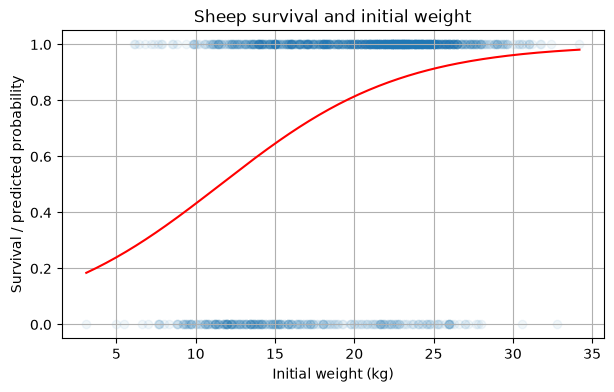

In [21]:
sheep = load('Sheep')
sheep_fit = smf.glm('survival ~ weight',sheep,family=sm.families.Binomial()).fit()
equation(sheep_fit,'logit(P(survival))')
coefficients(sheep_fit)
print(f'Odds ratio per kg: {np.exp(sheep_fit.params.weight):.2f}')
x = np.linspace(sheep.weight.min(),sheep.weight.max(),200)
plt.scatter(sheep.weight,sheep.survival,alpha=.06)
plt.plot(x,sheep_fit.predict(pd.DataFrame({'weight':x})),color='red')
plt.xlabel('Initial weight (kg)');plt.ylabel('Survival / predicted probability')
plt.title('Sheep survival and initial weight');plt.show()


(b)  For what weight values do the sheep have more than a 50% chance of survival?

The fitted probability exceeds 50% for weights **above 11.57 kg** (rounded threshold). 

A probability greater than 0.50 corresponds to positive log odds. Since the fitted slope is positive, solve the fitted logit equation for weight to obtain the threshold below. The fitted probability equals 0.50 exactly at the threshold; predictions far outside the observed weights require caution.


In [22]:
threshold = -sheep_fit.params.Intercept/sheep_fit.params.weight
print(f'Predicted survival probability > 0.50 for weight > {threshold:.2f} kg')
print(f'Observed weight range: {sheep.weight.min():.2f} to {sheep.weight.max():.2f} kg')


Predicted survival probability > 0.50 for weight > 11.57 kg
Observed weight range: 3.10 to 34.20 kg


## Problem 7.9.

The `SoreThroat` data file at the book’s website contains data from from a study$^{23}$ about *Y* = whether a patient having surgery had a sore throat on waking (1 = yes, 0 = no) as a function of *D* = duration of the surgery (in minutes) and *T* = type of device used to secure the airway (1 = tracheal tube, 0 = laryngeal mask airway).

(a) Fit a GLM using both explanatory variables as main effects. Interpret effects.

The fitted logit is **?1.42 + 0.07 D ? 1.66 T**. Each minute multiplies the odds by **1.07**; the tube-to-mask odds ratio is **0.19**, or about 81% lower odds at the same duration. Duration has p = 0.01, while device has p = 0.07. 

A binomial GLM with a logit link models sore-throat probability. Holding device constant, each additional minute multiplies the odds by exp(the duration coefficient). Holding duration constant, using a tracheal tube rather than a laryngeal mask multiplies the odds by exp(the device coefficient). These main effects assume a common duration slope for both devices.


In [23]:
throat = load('SoreThroat')
throat_main = smf.glm('Y ~ D + T',throat,family=sm.families.Binomial()).fit()
equation(throat_main,'logit(P(sore throat))')
coefficients(throat_main)
print(f'Odds ratio per minute: {np.exp(throat_main.params.D):.2f}')
print(f'Odds ratio, tracheal tube versus mask: {np.exp(throat_main.params['T']):.2f}')


logit(P(sore throat)) = -1.42 +0.07*D -1.66*T

,Estimate,SE,p-value
Intercept,-1.42,1.09,0.20
D,0.07,0.03,0.01
T,-1.66,0.92,0.07


Odds ratio per minute: 1.07
Odds ratio, tracheal tube versus mask: 0.19


(b) Fit a GLM permitting interaction between the explanatory variables. Interpret the effect of *D* at each category of *T*.

The fitted logit is **0.05 + 0.03 D ? 4.47 T + 0.07 DT**. The duration slopes are **0.03** for the mask and **0.10** for the tube, with per-minute odds ratios **1.03** and **1.11**, respectively (computed before rounding coefficients). The interaction p-value is **0.20**, so evidence that the duration slopes differ is weak. 

With interaction, the duration effect on log odds is the D coefficient for the mask (T = 0) and the sum of the D and D:T coefficients for the tracheal tube (T = 1). The corresponding odds ratios are reported below. The T coefficient compares devices at zero minutes; the device comparison at duration D is exp(beta_T + beta_DT D).


In [24]:
throat_interaction = smf.glm('Y ~ D * T',throat,family=sm.families.Binomial()).fit()
equation(throat_interaction,'logit(P(sore throat))')
coefficients(throat_interaction)
for t,label in [(0,'Laryngeal mask'),(1,'Tracheal tube')]:
    slope = throat_interaction.params.D+t*throat_interaction.params['D:T']
    print(f'{label}: duration log-odds slope = {slope:.2f}; odds ratio per minute = {np.exp(slope):.2f}')


logit(P(sore throat)) = 0.05 +0.03*D -4.47*T +0.07*D:T


,Estimate,SE,p-value
Intercept,0.05,1.47,0.97
D,0.03,0.03,0.41
T,-4.47,2.47,0.07
D:T,0.07,0.06,0.20


Laryngeal mask: duration log-odds slope = 0.03; odds ratio per minute = 1.03
Tracheal tube: duration log-odds slope = 0.10; odds ratio per minute = 1.11


## 7.10 Predicting Diabetes Using Logistic Regression

In this exercise, you will build a simple AI classification model using logistic regression to predict whether a patient has diabetes. You will use the Diabetes dataset available directly from sklearn.datasets.

### Task

Load the diabetes dataset, explore the features, and build a logistic regression model that predicts the presence of diabetes.
Then, discuss whether logistic regression is appropriate for this AI task based on what we have covered in class.

### Your Steps

1. Load the diabetes dataset from sklearn.

2. Split the data into training and test sets.

3. Fit a logistic regression model. *Hint: Scale the features if necessary.*

4. Evaluate accuracy, f1 score, precision, recall, and roc auc on the test set.

5. Write a short reflection: does logistic regression seem like a reasonable AI model for this problem? Why or why not?

### Starter Code

1. Load the diabetes dataset from sklearn

In [25]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.dummy import DummyClassifier
data = load_diabetes(as_frame=True)
X = data.data
progression = data.target
print(f'Observations: {X.shape[0]}; features: {X.shape[1]}')
print('Features:', ', '.join(X.columns))
display(X.describe().T)
display(progression.describe().to_frame('Disease progression'))
print('Missing feature values:', X.isna().sum().sum())


Observations: 442; features: 10
Features: age, sex, bmi, bp, s1, s2, s3, s4, s5, s6


,count,mean,std,min,25%,50%,75%,max
age,442.00,-0.00,0.05,-0.11,-0.04,0.01,0.04,0.11
sex,442.00,0.00,0.05,-0.04,-0.04,-0.04,0.05,0.05
bmi,442.00,-0.00,0.05,-0.09,-0.03,-0.01,0.03,0.17
bp,442.00,-0.00,0.05,-0.11,-0.04,-0.01,0.04,0.13
s1,442.00,-0.00,0.05,-0.13,-0.03,-0.00,0.03,0.15
s2,442.00,0.00,0.05,-0.12,-0.03,-0.00,0.03,0.20
s3,442.00,-0.00,0.05,-0.10,-0.04,-0.01,0.03,0.18
s4,442.00,-0.00,0.05,-0.08,-0.04,-0.00,0.03,0.19
s5,442.00,0.00,0.05,-0.13,-0.03,-0.00,0.03,0.13
s6,442.00,0.00,0.05,-0.14,-0.03,-0.00,0.03,0.14


,Disease progression
count,442.00
mean,152.13
std,77.09
min,25.00
25%,87.00
50%,140.50
75%,211.50
max,346.00


Missing feature values: 0


2. Split the data into training and test sets.

**Dataset clarification:** [sklearn's documentation](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html) identifies this as a regression dataset: its target is quantitative disease progression one year after baseline, not diabetes presence. Therefore the requested diagnosis task cannot be answered from these labels. To demonstrate the required logistic-regression workflow, define a surrogate outcome: progression above the **training-set median**. This is an educational threshold, not a diagnostic criterion. Split before calculating the threshold to avoid using test-target information.


In [26]:
X_train, X_test, progression_train, progression_test = train_test_split(
    X, progression, test_size=.20, random_state=42)
cutoff = progression_train.median()
y_train = (progression_train > cutoff).astype(int)
y_test = (progression_test > cutoff).astype(int)
print(f'Training-median progression cutoff: {cutoff:.2f}')
print(f'Training observations: {len(X_train)}; test observations: {len(X_test)}')
print(f'Above-cutoff fraction: training {y_train.mean():.2f}; test {y_test.mean():.2f}')


Training-median progression cutoff: 142.00
Training observations: 353; test observations: 89
Above-cutoff fraction: training 0.49; test 0.45


3. Fit a logistic regression model. *Hint: Scale the features if necessary.*

In [27]:
# The pipeline learns scaling only from training features.
classifier = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42))
classifier.fit(X_train,y_train)
print('Fitted standardized logistic regression on the training set.')


Fitted standardized logistic regression on the training set.


4. Evaluate accuracy, f1 score, precision, recall, and roc auc on the test set.

In [28]:
y_pred = classifier.predict(X_test)
y_probability = classifier.predict_proba(X_test)[:,1]
metrics = pd.Series({
    'Accuracy': accuracy_score(y_test,y_pred),
    'F1 score': f1_score(y_test,y_pred),
    'Precision': precision_score(y_test,y_pred),
    'Recall': recall_score(y_test,y_pred),
    'ROC AUC': roc_auc_score(y_test,y_probability)
},name='Test score')
display(metrics.to_frame())
baseline = DummyClassifier(strategy='most_frequent').fit(X_train,y_train)
print(f'Majority-class baseline test accuracy: {baseline.score(X_test,y_test):.2f}')


,Test score
Accuracy,0.76
F1 score,0.73
Precision,0.76
Recall,0.70
ROC AUC,0.84


Majority-class baseline test accuracy: 0.55


5. Reflection: is logistic regression appropriate?


On the held-out test set, accuracy is **0.76**, F1 **0.73**, precision **0.76**, recall **0.70**, and ROC AUC **0.84**. Accuracy exceeds the majority-class baseline of **0.55**. 

Logistic regression is a reasonable, interpretable baseline for the explicitly defined binary **higher-progression** outcome. It produces probabilities and assumes additive linear effects on the log odds; nonlinear effects or interactions could limit performance. The held-out metrics assess this surrogate task, with ROC AUC using probabilities rather than hard labels. A single split provides limited evidence and cross-validation would better assess stability. Dichotomizing progression loses information, so regression would be more natural for the original continuous target. These results cannot measure the ability to diagnose diabetes: that requires a dataset with actual diabetes-status labels.


&nbsp;
&nbsp;
&nbsp;
&nbsp;
&nbsp;
&nbsp;
&nbsp;
&nbsp;


----------------
$^{23}$ Described in “Binary Data” by D. Collett, *Encyclopedia of Biostatistics*, 2nd ed. (Wiley, 2005), pp. 439–446.

$^{29}$ Some lack of fit the last few days reflects the impact of increasing “social distancing.”

Data sources: [textbook dataset index](https://stat4ds.rwth-aachen.de/data/) (local copies in `data/`); [sklearn diabetes dataset documentation](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html). Calculations retain full precision; reported numeric results use two decimal places. Hypothetical sketches are explicitly identified.
